# ***Analysing Pharmaceutical Sales Data***

## ***Exploration des données***

In [27]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns 
dt = pd.read_csv("data/salesdaily-selected-columns.csv")
df= dt.copy()

In [28]:
 
print(f"dimenssion : {df.shape}\n")
print(f"noms des colonnes : {df.columns}\n")
print(f"types : {df.dtypes}\n")
df.head()

dimenssion : (2106, 10)

noms des colonnes : Index(['datum', 'M01AB', 'M01AE', 'N02BA', 'N02BE', 'N05B', 'N05C', 'R03',
       'R06', 'Year'],
      dtype='str')

types : datum        str
M01AB    float64
M01AE    float64
N02BA    float64
N02BE    float64
N05B     float64
N05C     float64
R03      float64
R06      float64
Year       int64
dtype: object



,datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Year
0,1/2/2014,0.0,3.67,3.4,32.40,7.0,0.0,0.0,2.0,2014
1,1/3/2014,8.0,4.00,4.4,50.60,16.0,0.0,20.0,4.0,2014
2,1/4/2014,2.0,1.00,6.5,61.85,10.0,0.0,9.0,1.0,2014
3,1/5/2014,4.0,3.00,7.0,41.10,8.0,0.0,3.0,0.0,2014
4,1/6/2014,5.0,1.00,4.5,21.70,16.0,2.0,6.0,2.0,2014


In [29]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2106 entries, 0 to 2105
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   datum   2106 non-null   str    
 1   M01AB   2106 non-null   float64
 2   M01AE   2106 non-null   float64
 3   N02BA   2106 non-null   float64
 4   N02BE   2106 non-null   float64
 5   N05B    2106 non-null   float64
 6   N05C    2106 non-null   float64
 7   R03     2106 non-null   float64
 8   R06     2106 non-null   float64
 9   Year    2106 non-null   int64  
dtypes: float64(8), int64(1), str(1)
memory usage: 183.0 KB


In [30]:
df.isnull().sum()

datum    0
M01AB    0
M01AE    0
N02BA    0
N02BE    0
N05B     0
N05C     0
R03      0
R06      0
Year     0
dtype: int64

In [31]:
df.duplicated().sum()

np.int64(0)

In [32]:
df=df.rename(columns={"datum":"date"})
df["date"] = pd.to_datetime(df["date"])
df["date"].dtype

dtype('<M8[us]')

In [33]:
df.describe()

,date,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Year
count,2106,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000
mean,2016-11-19 12:00:00,5.033683,3.895830,3.880441,29.917095,8.853627,0.593522,5.512262,2.900198,2016.401235
min,2014-01-02 00:00:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2014.000000
25%,2015-06-12 06:00:00,3.000000,2.340000,2.000000,19.000000,5.000000,0.000000,1.000000,1.000000,2015.000000
50%,2016-11-19 12:00:00,4.990000,3.670000,3.500000,26.900000,8.000000,0.000000,4.000000,2.000000,2016.000000
75%,2018-04-29 18:00:00,6.670000,5.138000,5.200000,38.300000,12.000000,1.000000,8.000000,4.000000,2018.000000
max,2019-10-08 00:00:00,17.340000,14.463000,16.000000,161.000000,54.833333,9.000000,45.000000,15.000000,2019.000000
std,NaN,2.737579,2.133337,2.384010,15.590966,5.605605,1.092988,6.428736,2.415816,1.665060


In [34]:
df.dtypes

date     datetime64[us]
M01AB           float64
M01AE           float64
N02BA           float64
N02BE           float64
N05B            float64
N05C            float64
R03             float64
R06             float64
Year              int64
dtype: object

## **1- Quel est le volume total des ventes pour chaque catégorie ATC ?**


M01AB    10600.937083
M01AE     8204.618646
N02BA     8172.209000
N02BE    63005.402708
N05B     18645.737500
N05C      1249.958333
R03      11608.822917
R06       6107.817500
dtype: float64


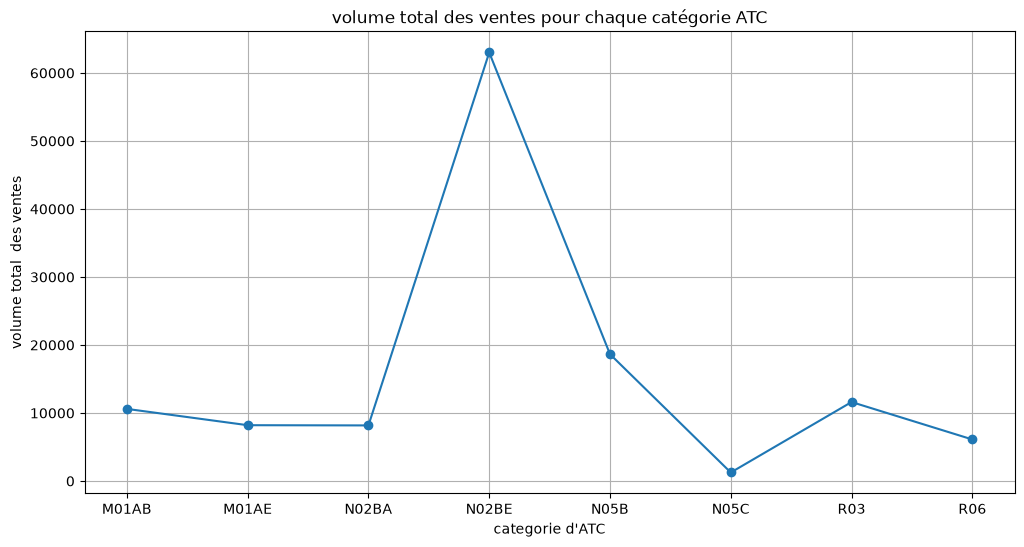

In [35]:
atc_list = ['M01AB', 'M01AE', 'N02BA', 'N02BE', 'N05B', 'N05C', 'R03','R06']
atc_total= df[atc_list].sum()
print(atc_total)
atc_total.plot(kind='line',figsize=(12,6),marker='o')
plt.title("volume total des ventes pour chaque catégorie ATC")
plt.xlabel("categorie d'ATC")
plt.ylabel("volume total  des ventes")
plt.grid()
plt.show()

### **Les résultats de l'analyse montrent que la catégorie ATC N02BE enregistre le volume total de ventes le plus élevé sur la période 2014–2019. Elle représente donc la catégorie dominante parmi les huit catégories étudiées.**

### **Est-ce que N02BE domine les ventes chaque année entre 2014 et 2019, ou est-ce seulement son total cumulé sur les six années qui est le plus élevé ?**

In [36]:

# atc_data= df.groupby('Year')[atc_list].sum()
# print(atc_data)


## **2- Quels sont les 3 médicaments les plus vendus en janvier 2015, juillet 2016 et septembre 2017 ?**

In [37]:
col = ['M01AB', 'M01AE', 'N02BA', 'N02BE', 'N05B', 'N05C', 'R03','R06']
df['month'] = df['date'].dt.strftime("%Y-%m")
df.head()

,date,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Year,month
0,2014-01-02,0.0,3.67,3.4,32.40,7.0,0.0,0.0,2.0,2014,2014-01
1,2014-01-03,8.0,4.00,4.4,50.60,16.0,0.0,20.0,4.0,2014,2014-01
2,2014-01-04,2.0,1.00,6.5,61.85,10.0,0.0,9.0,1.0,2014,2014-01
3,2014-01-05,4.0,3.00,7.0,41.10,8.0,0.0,3.0,0.0,2014,2014-01
4,2014-01-06,5.0,1.00,4.5,21.70,16.0,2.0,6.0,2.0,2014,2014-01


In [38]:
tbest=df.loc[df['month'].isin(["2015-01"]),col]


In [39]:
top_3 = tbest.sum().sort_values(ascending=False).head(3)

In [40]:
top_3

N02BE    1044.24
N05B      463.00
R03       177.25
dtype: float64

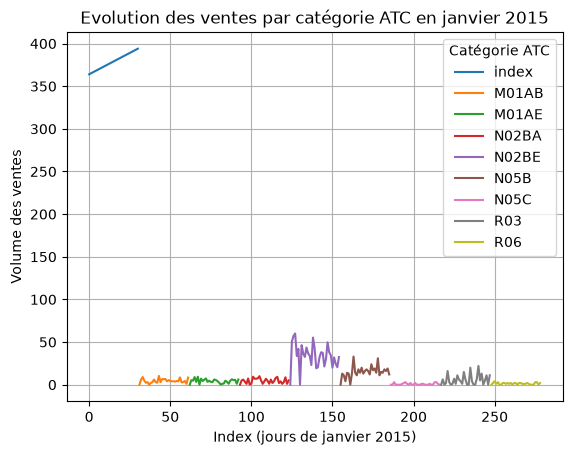

In [41]:
tbest_melted = tbest.reset_index(drop=False).melt(var_name='ATC', value_name='Ventes')
sns.lineplot(data=tbest_melted, x=tbest_melted.index, y='Ventes', hue='ATC')
plt.title("Evolution des ventes par catégorie ATC en janvier 2015")
plt.xlabel("Index (jours de janvier 2015)")
plt.ylabel("Volume des ventes")
plt.legend(title='Catégorie ATC')
plt.grid()
plt.show()

### **L'analyse des ventes du mois de janvier 2015 révèle que les trois catégories ATC ayant enregistré les volumes de ventes les plus élevés sont, dans l'ordre, N02BE, N05B et R03.**

In [42]:
tbest_16=df.loc[df['month'].isin(["2016-07"]),col]
top_3_16=tbest_16.sum().sort_values(ascending=False).head(3)

top_3_16

N02BE    652.362000
N05B     240.000000
M01AB    194.528333
dtype: float64

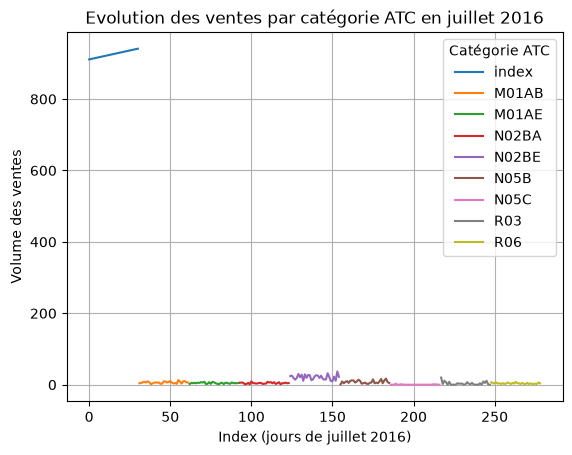

In [43]:
tbest_melted_16 = tbest_16.reset_index(drop=False).melt(var_name='ATC', value_name='Ventes')
sns.lineplot(data=tbest_melted_16, x=tbest_melted_16.index, y='Ventes', hue='ATC')
plt.title("Evolution des ventes par catégorie ATC en juillet 2016")
plt.xlabel("Index (jours de juillet 2016)")
plt.ylabel("Volume des ventes")
plt.legend(title='Catégorie ATC')
plt.grid()
plt.show()

###   **L'analyse des ventes du mois de juillet 2016 les trois catégories ATC ayant enregistré les volumes de ventes les plus élevés sont, dans l'ordre, N02BE, N05B et M01AB.**

In [44]:
tbest_17=df.loc[df['month'].isin(["2017-09"]),col]
top_3_17=tbest_17.sum().sort_values(ascending=False).head(3)

top_3_17

N02BE    863.75
N05B     223.00
R03      139.00
dtype: float64

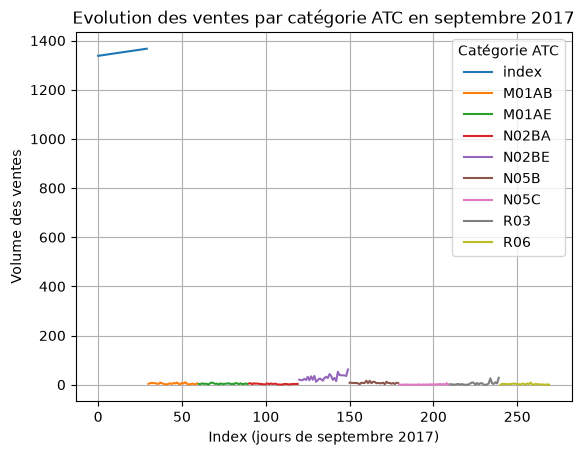

In [45]:
tbest_melted_17 = tbest_17.reset_index(drop=False).melt(var_name='ATC', value_name='Ventes')
sns.lineplot(data=tbest_melted_17, x=tbest_melted_17.index, y='Ventes', hue='ATC')
plt.title("Evolution des ventes par catégorie ATC en septembre 2017")
plt.xlabel("Index (jours de septembre 2017)")
plt.ylabel("Volume des ventes")
plt.legend(title='Catégorie ATC')
plt.grid()
plt.show()

###   **L'analyse des ventes du mois de septembre 2017 révèle que les trois catégories ATC ayant enregistré les volumes de ventes les plus élevés sont, dans l'ordre, N02BE, N05B et R03..**

## **3- Quel médicament a été le plus vendu en 2017 ?**

In [46]:
df.head()

,date,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Year,month
0,2014-01-02,0.0,3.67,3.4,32.40,7.0,0.0,0.0,2.0,2014,2014-01
1,2014-01-03,8.0,4.00,4.4,50.60,16.0,0.0,20.0,4.0,2014,2014-01
2,2014-01-04,2.0,1.00,6.5,61.85,10.0,0.0,9.0,1.0,2014,2014-01
3,2014-01-05,4.0,3.00,7.0,41.10,8.0,0.0,3.0,0.0,2014,2014-01
4,2014-01-06,5.0,1.00,4.5,21.70,16.0,2.0,6.0,2.0,2014,2014-01


In [47]:
y2017=df.loc[df["Year"] ==2017,col]
top2017= y2017.sum().sort_values(ascending=False)
top2017.head(1)

N02BE    9258.804833
dtype: float64

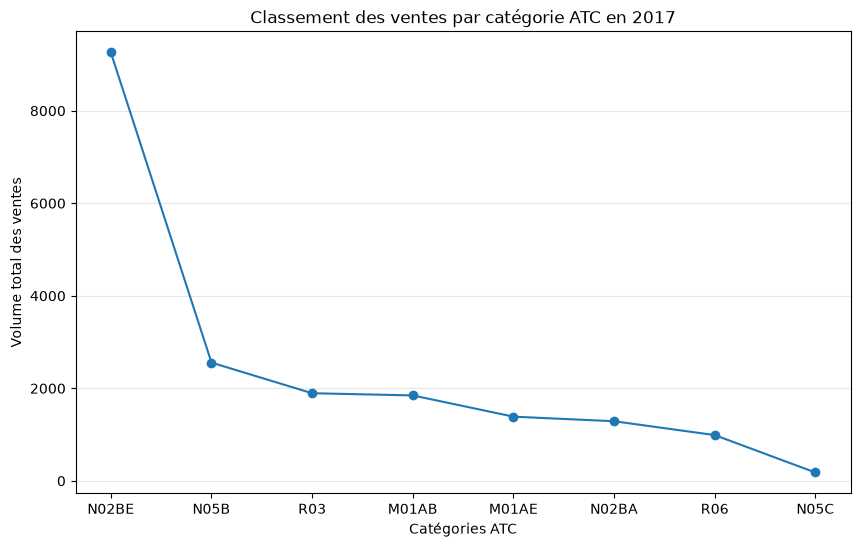

In [48]:
top2017.plot(kind='line',figsize=(10,6),marker='o')
plt.title("Classement des ventes par catégorie ATC en 2017")
plt.xlabel("Catégories ATC")
plt.ylabel("Volume total des ventes")
plt.grid(axis='y', alpha=0.3)

#### *À la suite de notre analyse des ventes de l'année 2017, nous constatons que la catégorie ATC **N02BE** est celle qui a enregistré le volume total de ventes le plus élevé sur cette année.*
#### *Elle occupe donc la première position parmi les huit catégories ATC étudiées.*

## **4- Quelle catégorie de médicaments possède la plus grande moyenne de ventes quotidiennes ?**

In [49]:
hebdoATC_mean= df[atc_list].mean().sort_values(ascending=False)
hebdoATC_mean.head()

N02BE    29.917095
N05B      8.853627
R03       5.512262
M01AB     5.033683
M01AE     3.895830
dtype: float64

C:\Users\Oumar DIARRASSOUBA\AppData\Local\Temp\ipykernel_23484\4015220940.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='categories ATC')


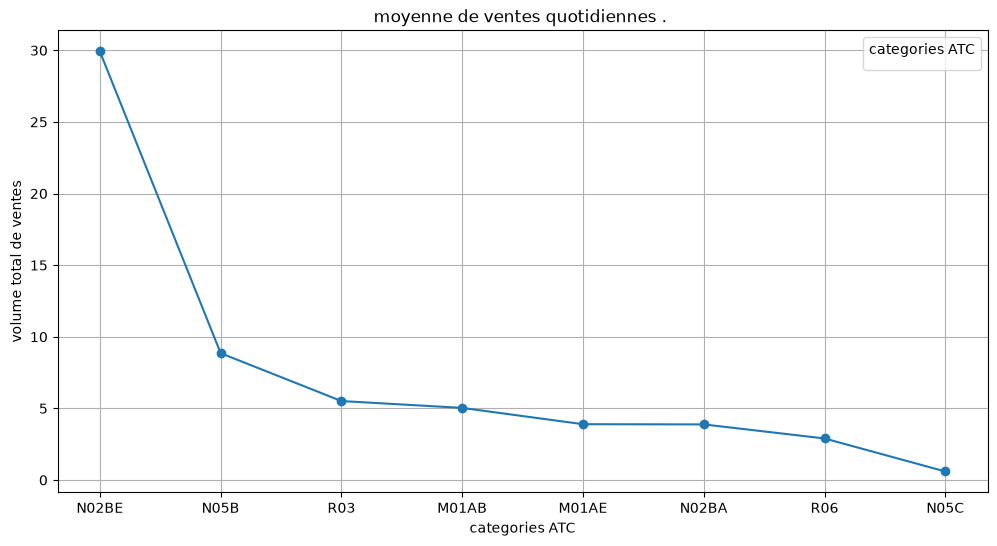

In [50]:
hebdoATC_mean.plot(kind='line',figsize=(12,6),marker='o')
plt.title("moyenne de ventes quotidiennes . ")
plt.xlabel('categories ATC')
plt.ylabel('volume total de ventes')
plt.legend(title='categories ATC')
plt.grid()
plt.show()

### **La catégorie ATC présentant la moyenne de ventes quotidiennes la plus élevée est N02BE, avec environ 29,92 unités de ventes par jour.**

## **5-Les médicaments respiratoires (R03) sont-ils vendus davantage pendant certains mois ?**

In [51]:
df['month_numb'] = df['date'].dt.month
month_R03=df.groupby('month_numb')['R03'].mean()
month_R03

month_numb
1     6.835980
2     6.896943
3     6.290323
4     5.771528
5     5.006944
6     4.350000
7     2.956989
8     3.102151
9     4.402315
10    7.208589
11    6.226667
12    7.916129
Name: R03, dtype: float64

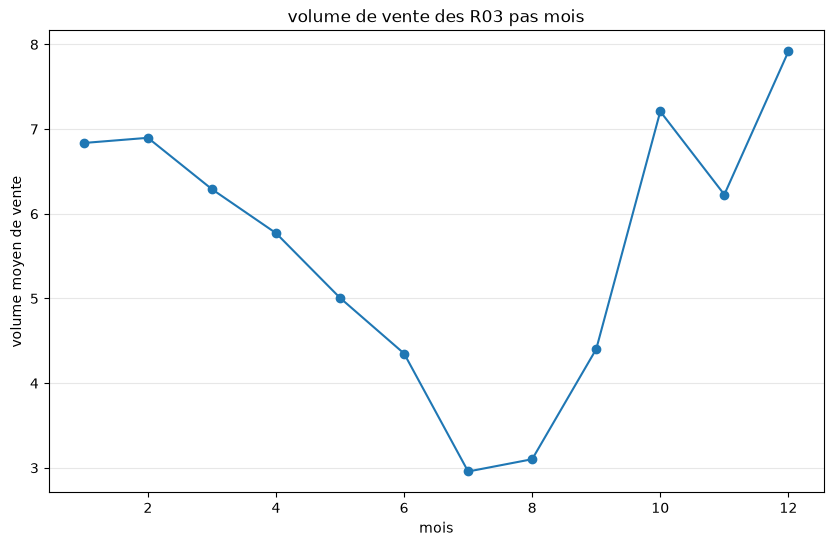

In [52]:
month_R03.plot(kind='line',figsize=(10,6),marker='o')
plt.title("volume de vente des R03 pas mois")
plt.xlabel("mois")
plt.ylabel("volume moyen de vente")
plt.grid(axis='y', alpha=0.3)
plt.show()

**L'analyse des ventes mensuelles de la catégorie R03 révèle une variation importante selon les mois. Les ventes moyennes les plus élevées sont enregistrées en décembre (7,92), octobre (7,21), février (6,90) et janvier (6,84). À l'inverse, juillet présente la moyenne la plus faible (2,96). Ces observations suggèrent une variation saisonnière des ventes de médicaments respiratoires, sans permettre à elles seules d'en déterminer les causes.**